# Cell differentiation with RNA velocity

Does the moment-Randers method recover the direction of differentiation of single cells, and how much of it can a Finsler MDS (Dagès et al., 2025) represent?

**What is real and what is modelled.** The RNA velocity of the cells (scVelo) is real. A single-cell dataset has no directed distances, so, as for the ocean currents (`globcurrent`), they are *modelled* from the velocity field by Zermelo navigation: a cell travels at unit speed in the PCA space against a wind proportional to its velocity, so going along the velocity is cheaper than going against it. The wind has norm at most $\beta<1$, the analogue of $\|b\|$. There is no ground truth beyond the velocity itself.

**What is measured.**
* *Direction*: cosine between the drift of a method and the velocity pushed into the same embedding (`push_forward`, the way scVelo draws velocity in an embedding). Ours and Perrault-Joncas & Meila (PJM) are read in the same 2D Isomap embedding. Finsler MDS has its own 3D embedding; its drift is the tangential part of its last axis.
* *Curl*: the share of the asymmetry of the edges that no potential explains. Finsler MDS has the drift of a gradient, so it cannot represent that share, whatever the optimiser. `gradient ceiling` is the cosine reached by the best such drift, $-\nabla\varphi$.

The velocity graph, PCA and cell types come from the scVelo pipeline. The files are produced by `preprocess_with_scvelo`; the notebook reads them from `CELL_DATA_DIR` (default `data/cells` at the root of the repository).

In [1]:
import os
import warnings

warnings.filterwarnings("ignore")  # deprecation notice of torch.jit at import

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.stats import spearmanr
from sklearn.neighbors import NearestNeighbors

from finsler_embedding import from_points
from finsler_embedding.experiments.baselines import perrault_joncas_meila
from finsler_embedding.experiments.finsler_mds_manifolds import finsler_mds_points, path_distances
from finsler_embedding.experiments.globcurrent.curl import edge_asymmetries, potential_drift, potential_fit
from finsler_embedding.experiments.graph import get_knn_graph
from finsler_embedding.experiments.palette import INK, categories
from finsler_embedding.experiments.lineage_cells.velocity import (
    DEFAULT_DIR, knn_average, load_velocity_data, push_forward, tangential_cosine, transition_matrix, wind,
    zermelo_distances,
)

DATA_DIR = Path(os.environ.get("CELL_DATA_DIR", DEFAULT_DIR))

BETA = 0.9      # strongest wind (99th percentile over the cells) over the speed of a cell, < 1
SMOOTH_K = 10   # the velocity of a cell is averaged over its SMOOTH_K nearest neighbours (itself included)
K = 10          # neighbours of the graph: edges of the curl diagnostic and of Finsler MDS, Isomap
ALPHA = 0.5     # strength of the canonical drift of Finsler MDS
SEED = 0

# Cell types kept for each dataset. Dentate gyrus: the lineage tree of the granule cells and glia, without the
# resident populations (endothelial, microglia, GABA, Cajal-Retzius, Cck-Tox, mossy), whose velocity is not a lineage.
DATASETS = {
    "pancreas": dict(cluster_key="clusters", keep=None, obs=("velocity_pseudotime",)),
    "dentategyrus": dict(
        cluster_key="clusters", obs=(),
        keep=["Radial Glia-like", "nIPC", "Neuroblast", "Granule immature", "Granule mature", "Astrocytes", "OPC", "OL"],
    ),
}

## The experiment for one dataset

1. Velocity of the cells in the PCA space: $T_{ij}\propto\exp(10\cos_{ij})$ on the velocity graph, expected displacement $\sum_j T_{ij}(x_j-x_i)$, averaged over the neighbours.
2. Wind $w_i$ (norm $\le\beta$) and directed distances $D_{ij}$, the Zermelo length of the straight segment from $i$ to $j$ in the wind $(w_i+w_j)/2$.
3. Curl of the asymmetry $(D_{ij}-D_{ji})/2$ on the k-NN graph: least-squares potential $\varphi$, share left over. Raw, and weighted by $1/s_{ij}$ ($s_{ij}$ the symmetric length of the edge) so that the sparse regions, with long edges, do not dominate.
4. Ours: `from_points` with the Isomap embedding. PJM on the same kernel and embedding. Finsler MDS on the directed shortest paths of the k-NN graph, in the canonical Randers space of dimension 3.

In [2]:
def curl_fractions(D, edges, n):
    """Share of the energy of the edge asymmetries that no potential explains: raw, and weighted by 1 / s_ij."""
    pairs, asymmetry = edge_asymmetries(edges, D[edges[:, 0], edges[:, 1]], n)
    symmetric = 0.5 * (D[pairs[:, 0], pairs[:, 1]] + D[pairs[:, 1], pairs[:, 0]]).numpy().astype(float)
    phi, raw = potential_fit(pairs, asymmetry, n)
    relative = potential_fit(pairs, asymmetry, n, 1 / symmetric)[1]
    return phi, raw, relative, pairs, asymmetry, symmetric


def summary(cosine):
    return dict(median=float(cosine.median()), q10=float(cosine.quantile(0.1)), positive=float((cosine > 0).float().mean()))


def run(name, beta=BETA, smooth_k=SMOOTH_K, k=K, alpha=ALPHA, seed=SEED):
    cfg = DATASETS[name]
    torch.manual_seed(seed)
    np.random.seed(seed)
    data = load_velocity_data(DATA_DIR / f"{name}_processed.h5ad", cfg["cluster_key"], cfg["keep"], k=k, obs_columns=cfg["obs"])
    x, labels = data["x"], data["labels"]
    n = len(x)

    # 1-2. velocity in the PCA space, wind, directed distances
    t = transition_matrix(data["cosines"])
    smoother = knn_average(x, smooth_k)
    w = wind(push_forward(t, x, smoother), beta)
    D = zermelo_distances(x, w)
    X = torch.as_tensor(x, dtype=torch.float32)

    # 3. curl of the asymmetry on the k-NN graph
    edges = get_knn_graph(X, k)
    lengths = D[edges[:, 0], edges[:, 1]]
    phi, raw, relative, pairs, asymmetry, symmetric = curl_fractions(D, edges, n)

    # 4a. ours: Isomap embedding, drift from the directed kernel
    masked = D.clone()
    masked.fill_diagonal_(float("inf"))
    bandwidth = float(masked.kthvalue(k, dim=1).values.median())  # the kernel reaches the k-th neighbour of a typical cell
    result = from_points(X, distances=D, bandwidth=bandwidth, embedding="isomap",
                         embedding_params={"n_neighbors": k}, n_components=2)
    Y = result.coordinates
    reference = torch.as_tensor(push_forward(t, Y.numpy().astype(np.float64), smoother), dtype=torch.float32)
    cosine = torch.nn.functional.cosine_similarity
    rows = {"ours": summary(cosine(result.drift, reference, dim=1))}

    # 4b. Perrault-Joncas and Meila: vector field of the antisymmetric part, same kernel, same embedding
    field = torch.as_tensor(perrault_joncas_meila.vector_field(result.kernel.numpy(), Y.numpy()), dtype=torch.float32)
    finite = torch.isfinite(field).all(dim=1)
    rows["Perrault-Joncas & Meila"] = summary(cosine(field[finite], reference[finite], dim=1))

    # 4c. Finsler MDS: its drift is the last axis; on the embedded cells, its tangential part
    Z = finsler_mds_points(path_distances(edges, lengths, n), alpha, seed)
    reference_Z = push_forward(t, Z.numpy().astype(np.float64), smoother)
    last_axis = torch.zeros(3)
    last_axis[-1] = -1.0  # towards cheaper travel, as the drift of our method
    rows["Finsler MDS"] = summary(tangential_cosine(Z, last_axis, reference_Z))

    # ceiling of any drift that is a gradient: the best potential, differentiated on the neighbours of the graph
    neighbours = torch.as_tensor(NearestNeighbors(n_neighbors=16).fit(x).kneighbors(return_distance=False)[:, 1:])
    gradient = potential_drift(Y, torch.eye(2).expand(n, 2, 2), phi, neighbours=neighbours)
    rows["gradient ceiling"] = summary(cosine(gradient, reference, dim=1))

    # where the curl sits: share of the weighted residual of the edges, per cell type
    residual = (asymmetry - (phi[pairs[:, 1]] - phi[pairs[:, 0]])) / symmetric
    energy = pd.DataFrame({"a": labels[pairs[:, 0]], "b": labels[pairs[:, 1]], "r2": residual**2, "a2": (asymmetry / symmetric) ** 2})
    per_type = pd.concat([energy.assign(type=energy.a), energy.assign(type=energy.b)]).groupby("type")[["r2", "a2"]].sum()
    per_type = pd.DataFrame({"cells": pd.Series(labels).value_counts(), "curl share": per_type.r2 / per_type.a2}).dropna()
    pseudotime = data["obs"].get("velocity_pseudotime")
    return dict(
        name=name, n=n, labels=labels, x=x, umap=data["umap"], t=t, smoother=smoother, w=w, D=D, edges=edges, phi=phi,
        curl_raw=raw, curl_relative=relative, methods=pd.DataFrame(rows).T, per_type=per_type, Y=Y.numpy(),
        reference=reference.numpy(), drift=result.drift.numpy(), field=field.numpy(), Z=Z.numpy(),
        admissible=float(result.admissible.float().mean()), bandwidth=bandwidth,
        pseudotime_rho=None if pseudotime is None else float(spearmanr(phi, pseudotime).statistic),
    )

In [3]:
results = {name: run(name) for name in DATASETS}
for name, r in results.items():
    print(f"{name}: {r['n']} cells, curl fraction {r['curl_raw']:.3f} (weighted {r['curl_relative']:.3f}), "
          f"kernel bandwidth {r['bandwidth']:.1f}, {r['admissible']:.0%} of the cells admissible")

pancreas: 3696 cells, curl fraction 0.035 (weighted 0.105), kernel bandwidth 49.8, 95% of the cells admissible
dentategyrus: 2565 cells, curl fraction 0.033 (weighted 0.072), kernel bandwidth 18.4, 98% of the cells admissible


## Direction of the drift

Cosine with the velocity pushed into the embedding of each method (median over the cells, 10% quantile, share of cells with a positive cosine). The gradient ceiling is the best a drift that is the gradient of a potential can do in our embedding.

In [4]:
table = pd.concat({name: r["methods"] for name, r in results.items()}, names=["dataset", "method"])
table.round(3)

median    q10  positive
dataset      method                                          
pancreas     ours                      0.880 -0.647     0.812
             Perrault-Joncas & Meila   0.912 -0.438     0.851
             Finsler MDS               0.394 -0.635     0.663
             gradient ceiling          0.783 -0.316     0.858
dentategyrus ours                      0.745 -0.829     0.692
             Perrault-Joncas & Meila   0.905 -0.229     0.864
             Finsler MDS               0.434 -0.453     0.748
             gradient ceiling          0.777 -0.356     0.855

## Other values of $\theta$ and of the strength of Finsler MDS

Two hyperparameters are not fixed by the data. $\theta\in[0,1]$ is the exponent of the degree normalisation of the kernel in our method (`from_points(theta=...)`, $\theta=0$ does not divide by the degree), and $\|\omega\|=\alpha$ the strength of the canonical drift of Finsler MDS. Neither is selected with the velocity, which is the only reference, so the table gives all values: ours for $\theta\in\{1,0.5,0\}$ on the same kernel, the same Isomap embedding and the same reference, and Finsler MDS for $\|\omega\|\in\{0.5,0.9\}$ (the second needs another run of the optimiser). The PJM field does not depend on $\theta$.


In [5]:
cosine = torch.nn.functional.cosine_similarity


def variants(name, thetas=(1.0, 0.5, 0.0), alphas=(0.5, 0.9), seed=SEED):
    """Ours for several theta (same kernel, embedding and reference as `run`) and Finsler MDS for several strengths."""
    r = results[name]
    n, x = r["n"], torch.as_tensor(r["x"], dtype=torch.float32)
    reference = torch.as_tensor(r["reference"])
    rows = {}
    for theta in thetas:
        result = from_points(x, distances=r["D"], bandwidth=r["bandwidth"], theta=theta, embedding="isomap",
                             embedding_params={"n_neighbors": K}, n_components=2)
        assert np.abs(result.coordinates.numpy() - r["Y"]).max() < 1e-5 * np.abs(r["Y"]).max()  # same embedding as `run`
        rows[f"ours, theta = {theta:g}"] = summary(cosine(result.drift, reference, dim=1))
    edges = r["edges"]
    distances = path_distances(edges, r["D"][edges[:, 0], edges[:, 1]], n)
    last_axis = torch.zeros(3)
    last_axis[-1] = -1.0
    for alpha in alphas:
        Z = torch.as_tensor(r["Z"]) if alpha == ALPHA else finsler_mds_points(distances, alpha, seed)  # `run` used ALPHA
        reference_Z = push_forward(r["t"], Z.numpy().astype(np.float64), r["smoother"])
        rows[f"Finsler MDS, |omega| = {alpha:g}"] = summary(tangential_cosine(Z, last_axis, reference_Z))
    return pd.DataFrame(rows).T


order = ["ours, theta = 1", "ours, theta = 0.5", "ours, theta = 0", "Perrault-Joncas & Meila",
         "Finsler MDS, |omega| = 0.5", "Finsler MDS, |omega| = 0.9", "gradient ceiling"]
table_variants = pd.concat({
    name: pd.concat([variants(name), results[name]["methods"].loc[["Perrault-Joncas & Meila", "gradient ceiling"]]]).loc[order]
    for name in DATASETS
}, names=["dataset", "method"])
table_variants.round(3)


median    q10  positive
dataset      method                                             
pancreas     ours, theta = 1              0.880 -0.647     0.812
             ours, theta = 0.5            0.927 -0.626     0.831
             ours, theta = 0              0.922 -0.617     0.833
             Perrault-Joncas & Meila      0.912 -0.438     0.851
             Finsler MDS, |omega| = 0.5   0.394 -0.635     0.663
             Finsler MDS, |omega| = 0.9   0.663 -0.723     0.742
             gradient ceiling             0.783 -0.316     0.858
dentategyrus ours, theta = 1              0.745 -0.829     0.692
             ours, theta = 0.5            0.875 -0.880     0.714
             ours, theta = 0              0.929 -0.882     0.751
             Perrault-Joncas & Meila      0.905 -0.229     0.864
             Finsler MDS, |omega| = 0.5   0.434 -0.453     0.748
             Finsler MDS, |omega| = 0.9   0.737 -0.582     0.787
             gradient ceiling             0.777 -0.356     0.855

## Curl

Is the asymmetry of these cells a difference of potentials? Where does the part that is not sit? The potential $\varphi$ is the best potential of the asymmetry; on the pancreas it can be compared with the velocity pseudotime of scVelo.

In [6]:
def sensitivity(name, smooth_ks=(1, 10, 30), seed=SEED):
    """Curl fraction (weighted) when the velocity is smoothed more or less, and when the wind is shuffled among the cells."""
    r = results[name]
    x, n = r["x"], r["n"]
    t = r["t"]
    edges = r["edges"]
    rows = {}
    for k in smooth_ks:
        w = wind(push_forward(t, x, knn_average(x, k)), BETA)
        _, raw, relative, *_ = curl_fractions(zermelo_distances(x, w), edges, n)
        rows[f"smoothing over {k} cells"] = dict(raw=raw, weighted=relative)
    shuffled = r["w"][np.random.default_rng(seed).permutation(n)]  # same winds, structure destroyed
    _, raw, relative, *_ = curl_fractions(zermelo_distances(x, shuffled), edges, n)
    rows["shuffled wind (no structure)"] = dict(raw=raw, weighted=relative)
    return pd.DataFrame(rows).T


pd.concat({name: sensitivity(name) for name in DATASETS}, names=["dataset", "velocity"]).round(3)

raw  weighted
dataset      velocity                                     
pancreas     smoothing over 1 cells        0.041     0.092
             smoothing over 10 cells       0.035     0.105
             smoothing over 30 cells       0.044     0.115
             shuffled wind (no structure)  0.735     0.700
dentategyrus smoothing over 1 cells        0.041     0.033
             smoothing over 10 cells       0.033     0.072
             smoothing over 30 cells       0.020     0.058
             shuffled wind (no structure)  0.614     0.644

In [7]:
for name, r in results.items():
    print(f"\n{name}: curl share of the weighted asymmetry per cell type")
    print(r["per_type"].sort_values("curl share", ascending=False).round(3).to_string())
    if r["pseudotime_rho"] is not None:
        print(f"Spearman correlation between the potential of the asymmetry and the velocity pseudotime: {r['pseudotime_rho']:+.2f}")


pancreas: curl share of the weighted asymmetry per cell type
               cells  curl share
Pre-endocrine    592       0.398
Beta             591       0.357
Alpha            481       0.295
Epsilon          142       0.215
Delta             70       0.141
Ngn3 high EP     642       0.067
Ngn3 low EP      262       0.052
Ductal           916       0.043
Spearman correlation between the potential of the asymmetry and the velocity pseudotime: -0.73

dentategyrus: curl share of the weighted asymmetry per cell type
                  cells  curl share
Radial Glia-like     51       0.437
OL                   50       0.149
Astrocytes          120       0.138
nIPC                 19       0.087
OPC                  53       0.076
Neuroblast          417       0.061
Granule immature    785       0.042
Granule mature     1070       0.021


## Figures

Unit arrows, a random subset of the cells. Left to right: the velocity in the UMAP of scVelo (check of the input), the velocity pushed into our Isomap embedding (the reference), our drift, and the Finsler MDS embedding seen from the side, its drift being the vertical axis.

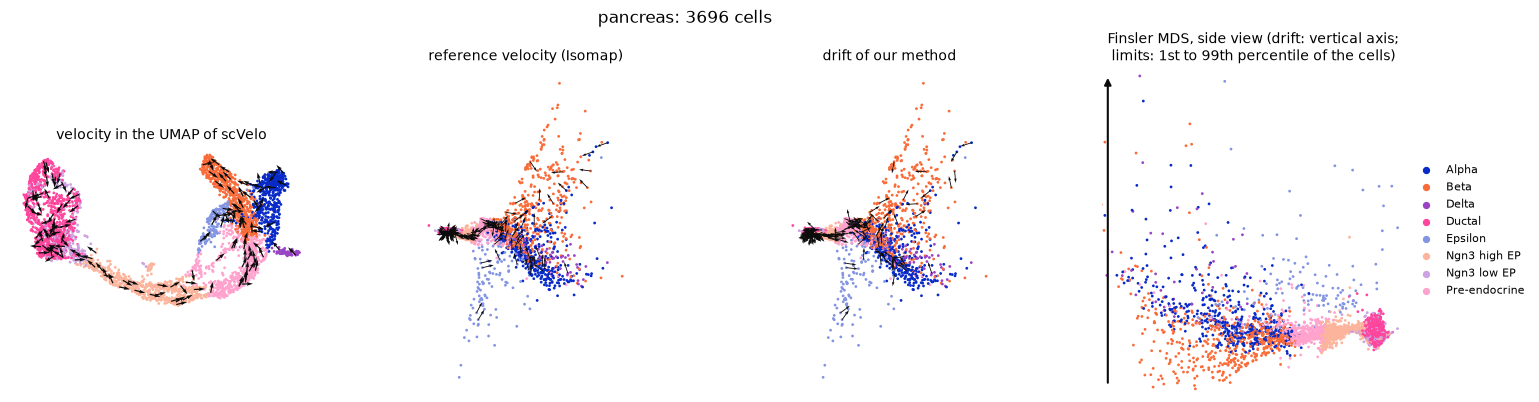

In [8]:
def figure(r, n_arrows=150, seed=SEED):
    labels = r["labels"]
    types = sorted(set(labels))
    palette = dict(zip(types, categories(len(types))))
    colors = np.array([palette[c] for c in labels])
    sel = np.random.default_rng(seed).choice(r["n"], min(n_arrows, r["n"]), replace=False)

    def arrows(ax, points, vectors, length):
        unit = vectors / (np.linalg.norm(vectors, axis=1, keepdims=True) + 1e-12)
        ax.quiver(*points[sel].T, *unit[sel].T, angles="xy", scale_units="xy", scale=1 / length, width=0.004, color=INK)

    def scatter(ax, points, title):
        ax.scatter(*points.T, c=colors, s=4, linewidths=0)
        ax.set_aspect("equal")
        ax.set_axis_off()
        ax.set_title(title, fontsize=10)
        return 0.04 * np.ptp(points, axis=0).max()

    fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
    if r["umap"] is not None:
        velocity_umap = push_forward(r["t"], r["umap"], r["smoother"])
        arrows(axes[0], r["umap"], velocity_umap, scatter(axes[0], r["umap"], "velocity in the UMAP of scVelo"))
    arrows(axes[1], r["Y"], r["reference"], scatter(axes[1], r["Y"], "reference velocity (Isomap)"))
    arrows(axes[2], r["Y"], r["drift"], scatter(axes[2], r["Y"], "drift of our method"))
    centred = r["Z"] - r["Z"].mean(0)
    in_plane = centred[:, :2] @ np.linalg.svd(centred[:, :2], full_matrices=False)[2].T
    side = np.stack([in_plane[:, 0], centred[:, 2]], axis=1)
    scatter(axes[3], side, "Finsler MDS, side view (drift: vertical axis;\nlimits: 1st to 99th percentile of the cells)")
    low, high = np.percentile(side, [1, 99], axis=0)
    margin = 0.08 * (high - low)
    axes[3].set_xlim(low[0] - margin[0], high[0] + margin[0])
    axes[3].set_ylim(low[1] - margin[1], high[1] + margin[1])
    axes[3].set_aspect("auto")
    axes[3].annotate("", xy=(0.02, 0.98), xytext=(0.02, 0.02), xycoords="axes fraction",
                     arrowprops=dict(arrowstyle="-|>", color=INK, lw=1.5))
    for c in types:
        axes[3].scatter([], [], color=palette[c], label=c, s=18)
    axes[3].legend(loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False, fontsize=8)
    fig.suptitle(f"{r['name']}: {r['n']} cells", y=1.02)
    return fig


figure(results["pancreas"])
plt.show()

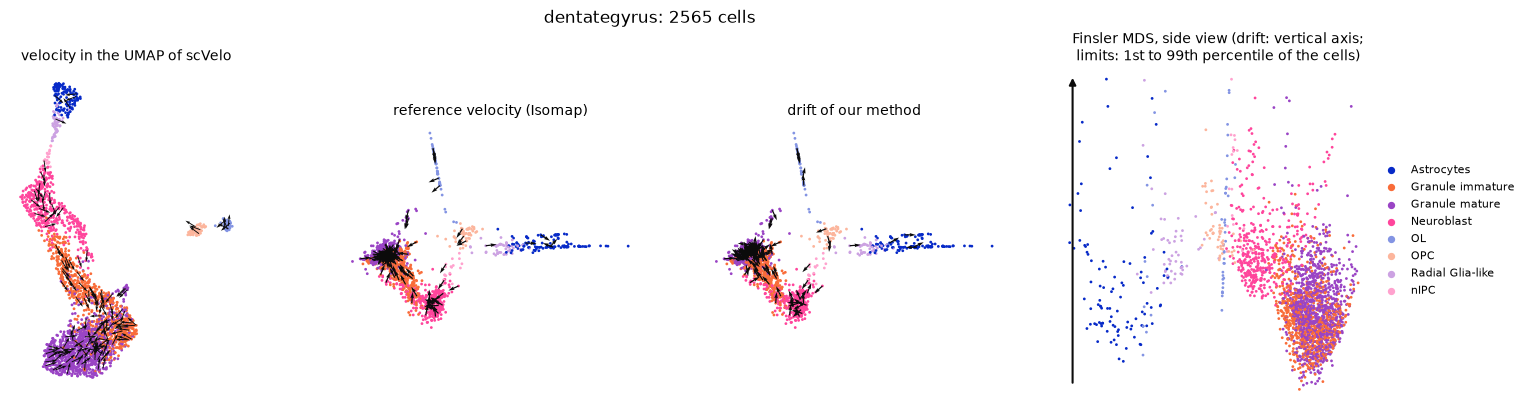

In [9]:
figure(results["dentategyrus"])
plt.show()

## Using another dataset

The pipeline needs an AnnData with `obsm["X_pca"]`, `uns["velocity_graph"]` (and `velocity_graph_neg`) and a column of cell types. `preprocess_with_scvelo` builds one from any dataset of `scvelo.datasets` (it needs `scvelo` and `scanpy`):

```python
from finsler_embedding.experiments.lineage_cells.velocity import preprocess_with_scvelo
preprocess_with_scvelo("gastrulation_erythroid", "data/cells/gastrulation_erythroid_processed.h5ad")
```

Then add an entry to `DATASETS` (cell-type column, cell types to keep, optional annotations) and run `run("gastrulation_erythroid")`.

This notebook needs a per-cell vector field (RNA velocity, or any other field in the PCA space) and builds the distances from it. It does not use the learned Finsler metric of the lineage-geodesics supplement, which `zebrafish.ipynb` uses and which is not installed on this machine.

## Reading the results (one seed, 2026-11 run)

* **These cells are not a curl example.** 90 to 97% of the asymmetry of the edges is a difference of potentials: the curl fraction is 0.03 to 0.10, against 0.6 to 0.7 for the same winds shuffled among the cells. Differentiation is a flow along a tree, without loops that a potential cannot absorb. On the pancreas the potential follows the developmental time (Spearman correlation $-0.73$ with the velocity pseudotime of scVelo), and the little curl sits in the late cells (pre-endocrine, beta, alpha) and, on the dentate gyrus, in the 51 radial glia-like cells. The argument against Finsler MDS that rests on curl is made by `globcurrent`, not by this dataset.
* **Direction.** Our drift follows the velocity (median cosine 0.88 on the pancreas, 0.75 on the dentate gyrus), but PJM follows it as well or better (0.91 on both), as on the other datasets: both have the direction, only ours has a calibrated metric and strength, which this experiment does not measure. The degree normalisation matters here: ours reaches 0.93 and 0.88 at $\theta=0.5$ and 0.92 and 0.93 at $\theta=0$ (table of the variants), and nothing in the data selects $\theta$, so the three values are reported. A negative cosine with ours is found on 19% of the cells of the pancreas and 31% of the dentate gyrus; the 2D Isomap collapses some stages onto a small region (see the figures), a likely cause that is not checked here.
* **Finsler MDS** reaches 0.39 and 0.43 with $\lVert\omega\rVert=0.5$ (the value of this notebook) and 0.66 and 0.74 with $\lVert\omega\rVert=0.9$, below the gradient ceiling (0.78 on both). With so little curl the gap is not due to the curl but to what the 3D embedding makes of these 30-dimensional cells, and it depends on the drift strength $\lVert\omega\rVert$. The baseline runs 2000 iterations without early stop, which lowers the stress by 26 to 28% compared with the former setting of 300 iterations and an early stop (pancreas, $\alpha=0.5$ and $0.9$). The ceiling is computed in our embedding and the cosine of Finsler MDS in its own, so the two are not on the same footing.
* **Limits.** The distances are modelled from the velocity, and the only reference is that velocity. One seed, one value of $\beta$ (0.9), one smoothing (10 cells); the sensitivity table shows that the curl fraction stays below 0.12 whether the velocity is smoothed over 1, 10 or 30 cells.